# Comprehensive Guide to Modern Agent Architectures

An **AI Agent** is an autonomous system that perceives its environment, makes reasoning decisions, and invokes tools or actions to achieve a given goal.

However, not all problems require full autonomy. Modern AI systems exist on a spectrum of control and autonomy, ranging from rigid sequential pipelines to multi-agent collaborative networks.

---

### 🎨 Taxonomy of Agent Architectures

![Taxonomy of Modern Agent Architectures](../../images/agent_patterns_overview.png)

---

### 🎨 Hierarchical Multi-Agent Architecture

![Hierarchical Multi-Agent Supervisor](../../images/multi_agent_supervisor.png)

---

### The 5 Core Architectures Explored in this Notebook:

| Architecture | Autonomy Level | Key Mechanism | Best Use Case |
| :--- | :--- | :--- | :--- |
| **1. Prompt Chaining / Workflow** | Low (Deterministic) | Fixed linear step-by-step pipeline | Data ETL, document parsing, deterministic reports |
| **2. ReAct (Reason + Act)** | Medium-High (Dynamic) | Iterative Thought -> Action -> Observation loop | Tool use, dynamic queries, live search & calculations |
| **3. Plan-and-Execute** | High (Structured) | Decouples strategic planning from step execution | Multi-step research, complex tasks, coding pipelines |
| **4. Self-Reflection (Reflexion)** | High (Iterative) | Actor-Critic evaluation & self-refinement | Code generation, essay writing, hallucination reduction |
| **5. Multi-Agent Supervisor** | Very High (Distributed) | Central orchestrator delegating to specialized agents | Enterprise automation, end-to-end software development |

---
## 0. Environment Setup & Free LLM Initialization

We use our centralized **`llm_config`** manager with automatic zero-downtime multi-model fallback.
Configurable via `.env` (`LLM_MODEL`), defaulting to `openai/gpt-oss-120b` with seamless failover to `qwen/qwen3.8-27b` and `openai/gpt-oss-20b` when rate limits are reached.

In [1]:
# Centralized LLM Configuration with Automatic Multi-Model Fallback
from llm_config import get_llm, list_free_models

# List verified free models and active status
list_free_models()

# Initialize unified model with zero-downtime automatic fallback
# (Configured via .env: LLM_MODEL, default: openai/gpt-oss-120b)
free_model = get_llm(temperature=0.7)
print(f"Active model: {free_model.model_name} (with automatic failover enabled)")


[*] VERIFIED FREE & ACTIVE MODELS REGISTRY
>> Current Active Model in .env: openai/gpt-oss-120b

* Model: openai/gpt-oss-120b [ACTIVE]
  - Provider:    GROQ
  - Context:     131,072 tokens
  - Best For:    Agents, Complex Reasoning, Production Tasks
  - Description: Flagship 120B open-weights model. Best reasoning, agent architectures, and complex tool calls.
--------------------------------------------------------------------------------
* Model: qwen/qwen3.8-27b
  - Provider:    GROQ
  - Context:     131,072 tokens
  - Best For:    General RAG, Fast Tool Calling, Structured Output
  - Description: High-efficiency 27B model. Fast, balanced latency and strong function calling.
--------------------------------------------------------------------------------
* Model: openai/gpt-oss-20b
  - Provider:    GROQ
  - Context:     131,072 tokens
  - Best For:    High-throughput tasks, Semantic Chunking, Simple Chains
  - Description: Ultra-fast 20B model. Low rate-limit consumption and minimal 

---
## 1. Architecture 1: Augmented LLM & Prompt Chaining (Workflow)

### Concept
Prompt chaining decomposes a large task into a **sequence of smaller, deterministic LLM calls**. Each step performs a specific transformation, and the output of step $N$ serves as the input to step $N+1$.

- **Autonomy**: Zero (the sequence is strictly hardcoded).
- **Failure Rate**: Very low (highly predictable and reproducible).
- **Cost & Latency**: Linear with number of steps.

In [2]:
# Input document
raw_text = (
    "Autonomous AI agents require three fundamental pillars to solve real-world problems: "
    "First, robust memory (both short-term context and persistent long-term state). "
    "Second, tool usage (invoking APIs, calculators, and databases). "
    "Third, self-reflection (evaluating intermediate mistakes and refining reasoning paths)."
)

# Step 1: Extraction & Analysis
step1_prompt = f"Extract the 3 core requirements from this text as concise points:\n\n{raw_text}"
step1_output = free_model.invoke(step1_prompt).content
print("--- STEP 1: Extracted Key Themes ---")
print(step1_output.strip())

# Step 2: Synthesis into Executive Memo
step2_prompt = (
    "Using these extracted themes, generate an executive memo for leadership:\n\n"
    f"{step1_output}"
)
step2_output = free_model.invoke(step2_prompt).content
print("\n--- STEP 2: Executive Summary Memo ---")
print(step2_output.strip())

--- STEP 1: Extracted Key Themes ---
- **Robust memory** – handling short‑term context and maintaining persistent long‑term state.  
- **Tool usage** – ability to invoke external APIs, calculators, databases, etc.  
- **Self‑reflection** – evaluating intermediate mistakes and refining reasoning paths.

--- STEP 2: Executive Summary Memo ---
**Executive Memo**  
**To:** Senior Leadership Team  
**From:** [Your Name], Head of AI Strategy  
**Date:** 12 Oct 2026  
**Subject:** Strategic Priorities for Next‑Generation Conversational AI – Memory, Tool Integration, and Self‑Reflection  

---

### 1. Overview  

Our recent research synthesis has identified three core capabilities that differentiate market‑leading conversational AI from baseline chatbots:

| Theme | Why It Matters | Business Impact |
|-------|----------------|-----------------|
| **Robust Memory** | Enables the model to retain short‑term context while persisting long‑term state across sessions, users, and domains. | • Higher u

---
## 2. Architecture 2: ReAct (Reason + Act) Loop

### Concept
Proposed by Yao et al. (2022), **ReAct** combines *Reasoning traces* (Thoughts) and *Task-specific Actions* (Tool calls) in an interleaved loop:
1. **Thought**: The model evaluates its current state and reasons about what to do next.
2. **Action**: The model emits a tool call (e.g. calculator, database query).
3. **Observation**: The tool executes and appends its result back to the model's message history.
4. **Loop**: The model reviews the observation and either calls another tool or outputs the final response.

- **Autonomy**: High (agent autonomously decides which tools to call and when to stop).

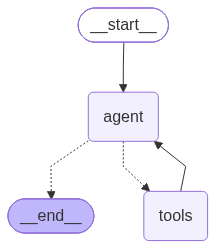

In [3]:
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage

# Define tool
@tool
def calculator(expression: str) -> str:
    """Evaluate a mathematical arithmetic expression."""
    print(f"Executing Tool 'calculator' with expression: {expression}")
    try:
        return str(eval(expression))
    except Exception as e:
        return f"Calculation Error: {e}"

tools = [calculator]
model_with_tools = free_model.bind_tools(tools)

# Node 1: Reasoner Node
def react_agent_node(state: MessagesState):
    res = model_with_tools.invoke(state["messages"])
    return {"messages": [res]}

# Build LangGraph ReAct Agent
builder = StateGraph(MessagesState)
builder.add_node("agent", react_agent_node)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "agent")
builder.add_conditional_edges("agent", tools_condition)  # Routes to 'tools' or END
builder.add_edge("tools", "agent")  # Observation loops back to Agent

react_agent = builder.compile()

# Visualize ReAct Agent Architecture
from IPython.display import Image, display
try:
    display(Image(react_agent.get_graph().draw_mermaid_png()))
except Exception:
    print(react_agent.get_graph().draw_ascii())


In [4]:

# Invoke agent
query = "What is 15 multiplied by 24, plus 140?"
response = react_agent.invoke({"messages": [HumanMessage(content=query)]})
print("\n--- Agent Final Response ---")
print(response["messages"][-1].content)


--- Agent Final Response ---
\(15 \times 24 = 360\)

\(360 + 140 = 500\)

So the result is **500**.


---
## 3. Architecture 3: Plan-and-Execute Agent

### Concept
In pure ReAct, the agent acts greedily step-by-step, which can lead to getting stuck in loops on complex, long-horizon tasks.

**Plan-and-Execute** explicitly decouples:
1. **Planner**: Creates an initial multi-step execution plan upfront.
2. **Executor**: Executes each step sequentially.
3. **Synthesizer / Replanner**: Evaluates overall completion and produces the final consolidated answer.

- **Advantage**: Superior for complex research queries and multi-faceted problem solving.

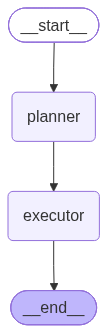

--- Generated Strategic Plan ---
1. Define the enterprise requirements and evaluation criteria (e.g., data privacy, latency, cost, scalability, maintenance effort, and expected performance gains) to create a structured framework for comparison.
2. Conduct a side‑by‑side analysis of Retrieval‑Augmented Generation (RAG) and fine‑tuning against the established criteria, summarizing strengths, trade‑offs, and recommended deployment approach for the organization.

--- Executed Synthesis ---
**Enterprise LLM Deployment: RAG vs. Fine‑Tuning**  
*Prepared as a step‑by‑step response to the requested strategic plan.*

---

## 1. Enterprise Requirements & Evaluation Criteria  

| Criterion | Why It Matters for Enterprises | Typical Enterprise Expectations |
|-----------|--------------------------------|---------------------------------|
| **Data Privacy & Security** | Sensitive customer, financial, or health data must stay protected (regulatory compliance: GDPR, HIPAA, CCPA, etc.). | • No raw dat

In [5]:
from typing import TypedDict, List

# State Schema
class PlanState(TypedDict):
    input_task: str
    plan: List[str]
    final_response: str

# Node 1: Strategic Planner
def planner_node(state: PlanState):
    prompt = (
        "You are a strategic planning agent. Break down the user task into exactly 2 high-level execution steps.\n"
        f"Task: {state['input_task']}\n"
        "Format as a numbered list (1. ..., 2. ...)."
    )
    res = free_model.invoke(prompt)
    steps = [line.strip() for line in res.content.strip().split("\n") if line.strip()]
    return {"plan": steps}

# Node 2: Executor & Synthesizer
def executor_node(state: PlanState):
    plan_str = "\n".join(state["plan"])
    prompt = (
        "You are an expert executor. Complete the user task by following this strategic plan step-by-step:\n\n"
        f"PLAN:\n{plan_str}\n\n"
        f"USER TASK: {state['input_task']}"
    )
    res = free_model.invoke(prompt)
    return {"final_response": res.content}

# Build Graph
pe_builder = StateGraph(PlanState)
pe_builder.add_node("planner", planner_node)
pe_builder.add_node("executor", executor_node)
pe_builder.add_edge(START, "planner")
pe_builder.add_edge("planner", "executor")
pe_builder.add_edge("executor", END)
pe_graph = pe_builder.compile()

# Visualize Plan-and-Execute Architecture
from IPython.display import Image, display
try:
    display(Image(pe_graph.get_graph().draw_mermaid_png()))
except Exception:
    print(pe_graph.get_graph().draw_ascii())

# Run Plan-and-Execute
task = "Compare RAG vs Fine-Tuning for enterprise LLM deployment."
result = pe_graph.invoke({"input_task": task})

print("--- Generated Strategic Plan ---")
for step in result["plan"]:
    print(step)
print("\n--- Executed Synthesis ---")
print(result["final_response"].strip())

---
## 4. Architecture 4: Self-Reflection / Reflexion (Actor + Critic Loop)

### Concept
Standard LLMs produce output in a single forward pass without verifying their work.

In **Reflexion** (Shinn et al., 2023):
1. **Actor**: Generates an initial draft or code solution.
2. **Critic**: Evaluates the draft against quality rubrics and produces constructive feedback.
3. **Router**: If criteria are satisfied -> `END`; otherwise loops back to Actor for revision (with a maximum iteration cap).

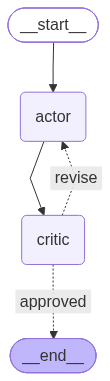

--- Final Actor Output (After Self-Correction) ---
A generator in Python is a function that uses the `yield` keyword to return an iterator that lazily produces values one at a time—preserving its execution state between yields and generating items on‑the‑fly without storing the entire sequence in memory, thus offering superior memory efficiency.

✅ Refinement loop completed in 2 iterations!


In [6]:
class ReflectionState(TypedDict):
    task: str
    draft: str
    critique: str
    iteration: int
    is_approved: bool

# Node 1: Actor
def actor_node(state: ReflectionState):
    curr_iter = state.get("iteration", 0)
    if curr_iter == 0:
        prompt = f"Write a concise 1-sentence technical definition for: {state['task']}"
    else:
        prompt = (
            f"Revise this draft to address the critique:\n"
            f"Draft: {state['draft']}\n"
            f"Critique: {state['critique']}\n"
            f"Provide the revised 1-sentence definition:"
        )
    res = free_model.invoke(prompt)
    return {"draft": res.content.strip(), "iteration": curr_iter + 1}

# Node 2: Critic / Evaluator
def critic_node(state: ReflectionState):
    prompt = (
        "Evaluate this definition of Python generators:\n"
        f"'{state['draft']}'\n\n"
        "Rubric: Must explicitly mention the 'yield' keyword and memory efficiency.\n"
        "If it meets both, reply with ONLY 'APPROVED'. Otherwise provide brief constructive critique."
    )
    res = free_model.invoke(prompt)
    content = res.content.strip()
    passed = "APPROVED" in content.upper() or state["iteration"] >= 2
    return {"critique": content, "is_approved": passed}

# Router
def check_approval(state: ReflectionState) -> str:
    return "approved" if state["is_approved"] else "revise"

# Build Graph
ref_builder = StateGraph(ReflectionState)
ref_builder.add_node("actor", actor_node)
ref_builder.add_node("critic", critic_node)

ref_builder.add_edge(START, "actor")
ref_builder.add_edge("actor", "critic")
ref_builder.add_conditional_edges("critic", check_approval, {"approved": END, "revise": "actor"})

reflection_agent = ref_builder.compile()

# Visualize Self-Reflection Architecture
from IPython.display import Image, display
try:
    display(Image(reflection_agent.get_graph().draw_mermaid_png()))
except Exception:
    print(reflection_agent.get_graph().draw_ascii())

# Run Reflection
task_desc = "What is a generator in Python?"
output = reflection_agent.invoke({"task": task_desc, "iteration": 0, "is_approved": False})

print("--- Final Actor Output (After Self-Correction) ---")
print(output["draft"])
print(f"\n✅ Refinement loop completed in {output['iteration']} iterations!")

---
## 5. Architecture 5: Multi-Agent Collaboration (Hierarchical Supervisor)

### Concept
When tasks require cross-disciplinary capabilities (e.g. Researching + Coding + Security Auditing), a single agent prompt becomes bloated.

A **Hierarchical Multi-Agent Supervisor** solves this:
- **Supervisor (Orchestrator)**: Evaluates the project status and delegates tasks to specialized worker agents.
- **Worker Agents**: Focused sub-agents with specialized tools and prompts.
- **Termination**: The Supervisor reviews worker deliverables and returns `FINISH` when all objectives are fulfilled.

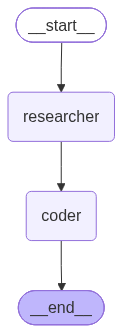

--- Mission: Research & Code Implementation ---
Researcher Deliverable:
## Binary Search – Core Algorithmic Ideas  

| Aspect | What you need to know |
|--------|-----------------------|
| **Pre‑condition** | The input sequence must be **sorted** (asce ...

Coder Deliverable:
Below is a **self‑contained, idiomatic Python implementation** of binary search that follows the ideas in the research notes.  
It includes:

* An **iterative** version (O(1) extra space) – the one you’ll use in production.  
* A **recursive** version (O(log n) call‑stack space) – useful for teaching or when you prefer a functional style.  
* Optional support for **descending‑sorted** sequences.  
* A tiny **lower‑bound** helper (first element ≥ target) that shows how the same skeleton can be reused for the classic “bisect‑style” variants.

```python
from __future__ import annotations
from typing import Sequence, TypeVar, Callable, Optional

T = TypeVar("T")                     # Element type – must be comparable


In [7]:
class TeamState(TypedDict):
    mission: str
    research_notes: str
    code_output: str
    next_step: str

# Worker 1: Researcher Agent
def researcher_node(state: TeamState):
    prompt = f"Provide key algorithmic principles and time complexity for: {state['mission']}"
    res = free_model.invoke(prompt)
    return {"research_notes": res.content.strip(), "next_step": "coder"}

# Worker 2: Coder Agent
def coder_node(state: TeamState):
    prompt = (
        f"Using these research notes, write a clean Python implementation:\n"
        f"{state['research_notes']}\n"
        f"Mission: {state['mission']}"
    )
    res = free_model.invoke(prompt)
    return {"code_output": res.content.strip(), "next_step": "FINISH"}

# Supervisor Router
def supervisor_router(state: TeamState) -> str:
    if not state.get("research_notes"):
        return "researcher"
    elif not state.get("code_output"):
        return "coder"
    return "FINISH"

# Build Supervisor Team Graph
team_builder = StateGraph(TeamState)
team_builder.add_node("researcher", researcher_node)
team_builder.add_node("coder", coder_node)

team_builder.add_edge(START, "researcher")
team_builder.add_edge("researcher", "coder")
team_builder.add_edge("coder", END)

team_graph = team_builder.compile()

# Visualize Multi-Agent Supervisor Architecture
from IPython.display import Image, display
try:
    display(Image(team_graph.get_graph().draw_mermaid_png()))
except Exception:
    print(team_graph.get_graph().draw_ascii())

# Run multi-agent team mission
mission_input = "Binary Search algorithm in Python"
team_result = team_graph.invoke({"mission": mission_input})

print("--- Mission: Research & Code Implementation ---")
print("Researcher Deliverable:")
print(team_result["research_notes"][:180], "...\n")
print("Coder Deliverable:")
print(team_result["code_output"].strip())
print("\n✅ Multi-agent collaboration completed!")

---
## 6. Architecture Comparison & Decision Guide

| Architecture | Autonomy | Cost / Latency | Primary Failure Mode | Best For |
| :--- | :--- | :--- | :--- | :--- |
| **Prompt Chaining** | Very Low | Lowest ($) | Brittleness to unexpected inputs | Form extraction, linear pipelines, report formatting |
| **ReAct Loop** | Medium-High | Medium ($$) | Infinite loops, wandering context | Tool calling, real-time web search, dynamic queries |
| **Plan-and-Execute** | High | Medium ($$) | Flawed upfront plan | Complex multi-step research, structured analyses |
| **Self-Reflection (Reflexion)** | High | Higher ($$$) | Critic hallucination or infinite loops | Code generation, high-accuracy writing, edge case fixes |
| **Multi-Agent Supervisor** | Highest | Highest ($$$$) | Inter-agent miscommunication, coordination overhead | Complex software projects, end-to-end multi-role tasks |

> **Rule of Thumb**: Start with the simplest architecture that solves your problem (Prompt Chaining or ReAct). Only escalate to Plan-and-Execute, Reflection, or Multi-Agent teams when a single agent demonstrably fails due to task complexity or context exhaustion.